In [ ]:
#PROJECT TITLE

#Public Transport Utilization Trends – An Exploratory Data Analysis Using Python

#INTRODUCTION

#This project analyses public transport utilization data using Python.
#It explores passenger demand, bus occupancy, route utilization,
#and fuel consumption through statistical analysis and data visualization.

#OBJECTIVES

#1. To analyse passenger utilization across different months.
#2. To compare occupancy rates among bus types.
#3. To identify routes with high passenger demand.
#4. To examine the relationship between distance travelled and fuel consumption.
#5. To present findings using graphs and statistical summaries.

#TOOLS USED

#Python, Pandas, NumPy, Matplotlib, and Google Colab.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("APSRTC Public Transportation Data.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

df = df.drop_duplicates()

print("Duplicate records removed")

print(df.describe(include="all"))

   bus_id                 route      bus_type       depot        date  \
0  AP0001     Kurnool-Hyderabad      Volvo AC      Guntur  26-11-2024   
1  AP0002   Anantapur-Bangalore       Sleeper    Tirupati  03-10-2024   
2  AP0003  Hyderabad-Vijayawada      Volvo AC  Vijayawada  06-07-2024   
3  AP0004       Eluru-Hyderabad  Semi-Sleeper     Kurnool  02-11-2024   
4  AP0005     Kurnool-Hyderabad       Sleeper   Hyderabad  20-09-2024   

   capacity  passengers  occupancy_rate  distance_km  fare_per_passenger  \
0        49          32           65.77       326.58              908.75   
1        36          14           41.42       291.91              770.66   
2        49          43           89.26       238.41              277.49   
3        63          52           83.97       347.55              199.64   
4        44          31           70.62       444.88              591.89   

    revenue  fuel_consumed_liters      month day_of_week  
0  29079.96                 75.73   November 

In [ ]:
df["Date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")

df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.day_name()

print(df.head())

   bus_id                 route      bus_type       depot        date  \
0  AP0001     Kurnool-Hyderabad      Volvo AC      Guntur  26-11-2024   
1  AP0002   Anantapur-Bangalore       Sleeper    Tirupati  03-10-2024   
2  AP0003  Hyderabad-Vijayawada      Volvo AC  Vijayawada  06-07-2024   
3  AP0004       Eluru-Hyderabad  Semi-Sleeper     Kurnool  02-11-2024   
4  AP0005     Kurnool-Hyderabad       Sleeper   Hyderabad  20-09-2024   

   capacity  passengers  occupancy_rate  distance_km  fare_per_passenger  \
0        49          32           65.77       326.58              908.75   
1        36          14           41.42       291.91              770.66   
2        49          43           89.26       238.41              277.49   
3        63          52           83.97       347.55              199.64   
4        44          31           70.62       444.88              591.89   

    revenue  fuel_consumed_liters      month day_of_week       Date  Day  \
0  29079.96                 

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nSummary Statistics:")
print(df.describe())

print("\nAverage Passenger Count:")
print(df["passengers"].mean())

print("\nMaximum Passenger Count:")
print(df["passengers"].max())

print("\nMinimum Passenger Count:")
print(df["passengers"].min())

Dataset Shape: (1000, 18)

Column Names:
['bus_id', 'route', 'bus_type', 'depot', 'date', 'capacity', 'passengers', 'occupancy_rate', 'distance_km', 'fare_per_passenger', 'revenue', 'fuel_consumed_liters', 'month', 'day_of_week', 'Date', 'Day', 'Month', 'Weekday']

Summary Statistics:
          capacity   passengers  occupancy_rate  distance_km  \
count  1000.000000  1000.000000     1000.000000  1000.000000   
mean     53.290000    36.832000       69.990930   374.287420   
min      36.000000     7.000000       20.000000    62.870000   
25%      49.000000    29.000000       58.402500   282.617500   
50%      55.000000    37.000000       71.190000   354.800000   
75%      59.000000    45.000000       83.382500   458.635000   
max      63.000000    63.000000      100.000000   699.590000   
std       7.917739    11.204433       18.038766   123.690147   

       fare_per_passenger       revenue  fuel_consumed_liters  \
count         1000.000000   1000.000000           1000.000000   
mean   

In [ ]:
weekday_usage = df.groupby("Weekday")["passengers"].mean()

print(weekday_usage)

Weekday
Friday       37.089655
Monday       37.553957
Saturday     37.253333
Sunday       36.500000
Thursday     36.123377
Tuesday      36.146853
Wednesday    37.316239
Name: passengers, dtype: float64


In [ ]:
depot_usage = df.groupby("depot")["passengers"].sum()

print(depot_usage.sort_values(ascending=False).head(10))

depot
Visakhapatnam    5861
Vijayawada       5829
Nellore          5292
Guntur           5208
Kurnool          5132
Tirupati         4894
Hyderabad        4616
Name: passengers, dtype: int64


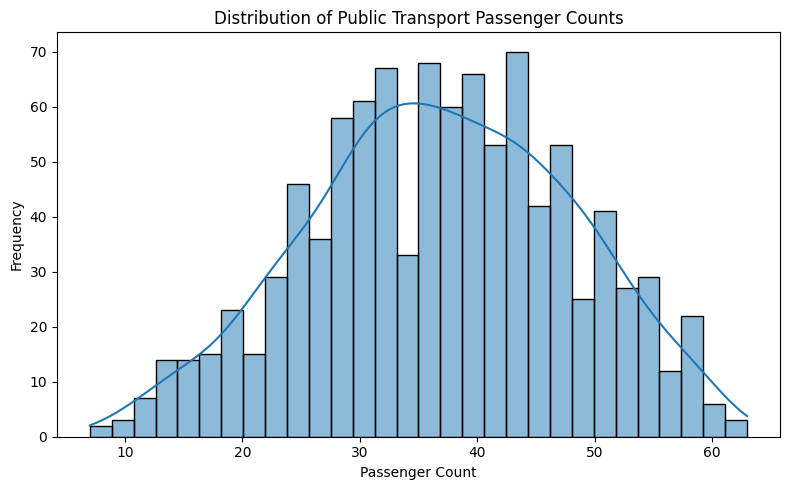

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["passengers"].dropna(), bins=30, kde=True)

plt.title("Distribution of Public Transport Passenger Counts")
plt.xlabel("Passenger Count")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

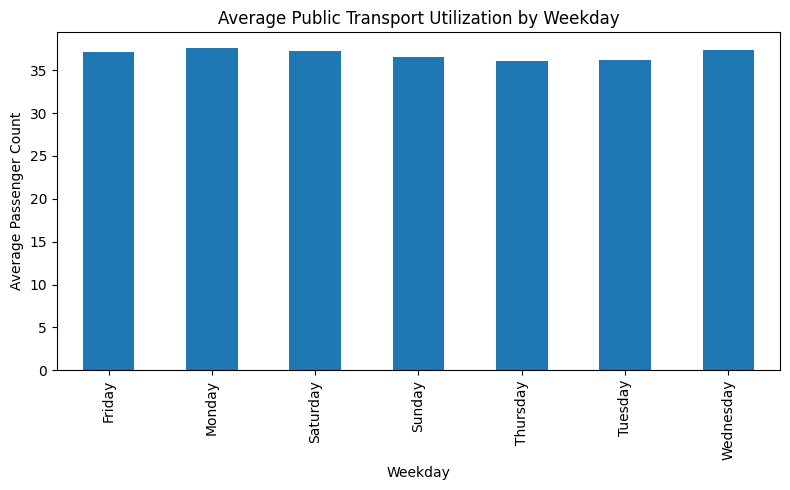

In [ ]:
weekday_usage = df.groupby("Weekday")["passengers"].mean()

weekday_usage.plot(kind="bar", figsize=(8, 5))

plt.title("Average Public Transport Utilization by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Passenger Count")

plt.tight_layout()
plt.show()

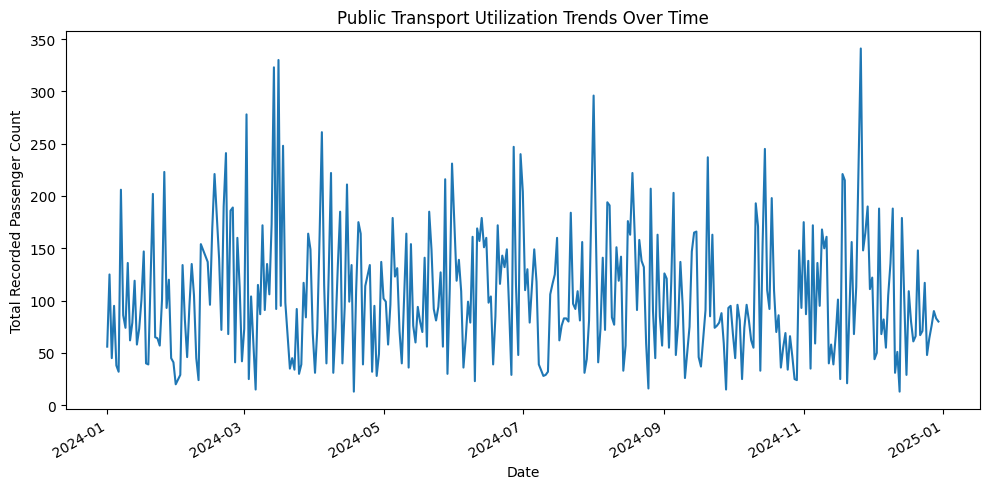

In [ ]:
daily_usage = df.groupby("Date")["passengers"].sum()

daily_usage.plot(figsize=(10, 5))

plt.title("Public Transport Utilization Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Total Recorded Passenger Count")

plt.tight_layout()
plt.show()

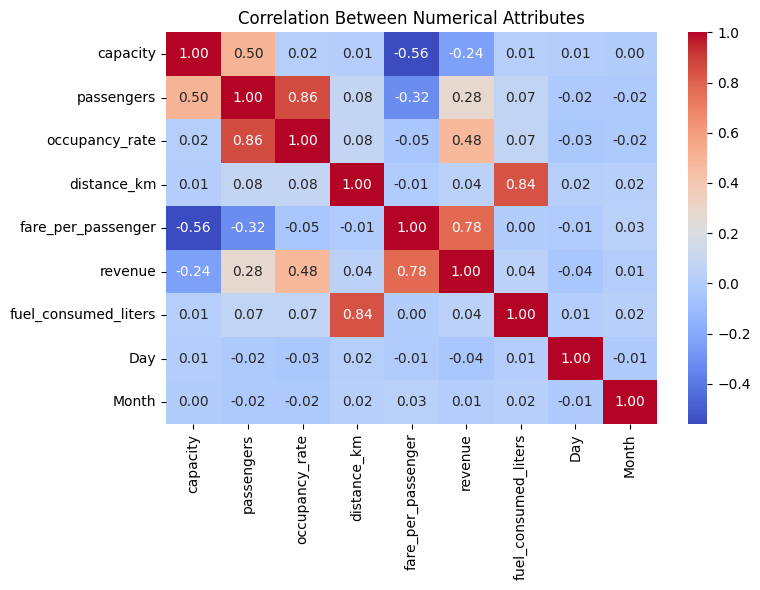

In [ ]:
numeric_data = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Attributes")

plt.tight_layout()
plt.show()

In [ ]:
column = df["passengers"]

print("Mean:", column.mean())
print("Median:", column.median())
print("Mode:", column.mode().tolist())
print("Standard Deviation:", column.std())
print("Minimum:", column.min())
print("Maximum:", column.max())
print("Variance:", column.var())

Mean: 36.832
Median: 37.0
Mode: [32]
Standard Deviation: 11.204432842197566
Minimum: 7
Maximum: 63
Variance: 125.53931531531542


In [ ]:
numeric_data = df.select_dtypes(include="number")

print(numeric_data.corr())

                      capacity  passengers  occupancy_rate  distance_km  \
capacity              1.000000    0.503737        0.015133     0.011648   
passengers            0.503737    1.000000        0.861752     0.080856   
occupancy_rate        0.015133    0.861752        1.000000     0.081226   
distance_km           0.011648    0.080856        0.081226     1.000000   
fare_per_passenger   -0.560210   -0.318453       -0.046417    -0.009357   
revenue              -0.240201    0.279407        0.479666     0.037150   
fuel_consumed_liters  0.014485    0.069060        0.070203     0.843623   
Day                   0.011304   -0.020595       -0.034564     0.015503   
Month                 0.004954   -0.018094       -0.020829     0.022954   

                      fare_per_passenger   revenue  fuel_consumed_liters  \
capacity                       -0.560210 -0.240201              0.014485   
passengers                     -0.318453  0.279407              0.069060   
occupancy_rate       

CONCLUSION This project uses Python to perform exploratory data analysis on public transport utilization data. Pandas is used for data processing and statistical analysis, while Matplotlib is used to visualize passenger demand, occupancy rates, route utilization, and fuel consumption. The graphs and statistical results help identify patterns in the dataset. The findings can support further investigation into public transport demand and operational efficiency.